[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/exercises/solutions/ex_05_blue_carbon_solutions.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🌿 Solutions: Ecosystem health, biodiversity & blue carbon
### Space Academy 2026 · Hyperspectral course · Week 2 — Project scoping and use case definition (Practical)

Check how good the simple mangrove proxy of notebook 05 really is, find out what makes mangroves spectrally unique, learn a better rule from data, and turn the result into a blue-carbon estimate — with honest uncertainty — for the mangroves of Jiquilisco Bay, El Salvador.

These exercises accompany the theme notebook [`05_ecosystem_health_blue_carbon.ipynb`](../https://github.com/Tnecniv-Teikram/813-hyperspectral-hackathon/blob/main/05_ecosystem_health_blue_carbon.ipynb). Run that notebook first
(or at least read it) — here we reuse its scene and indices, loaded with the course helper module `hsi_utils`.

> 🧑‍🏫 **Instructor version** — worked solutions with outputs. Students get the version without solutions in `exercises/`.

**What you will practise**
- Precision, recall and IoU of a map against a reference
- Spectral differences between mangroves and other vegetation (NIR, SWIR, red edge)
- Training and spatially testing an interpretable decision tree
- Why a model only knows the classes it was trained on
- Propagating map and carbon-density uncertainty into a carbon stock

**Data**
- `20250223_165546_32_4001` — Jiquilisco Bay, Usulután, El Salvador (23 Feb 2025)
- `data/labels/…_worldcover2021_30m.tif` — ESA WorldCover 2021 on the Tanager grid (class 95 = mangroves)

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## Setup

In [1]:
# hsi_utils.py lives in the course folder (../.. from here)
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))

# On Google Colab: upload hsi_utils.py next to this notebook, change the line above to
# sys.path.insert(0, ".") and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests

import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

Load the scene and the bands used in the theme notebook. `hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

Scene      : 20250223_165546_32_4001  (Usulután, El Salvador)
File       : /home/course/notebooks/20250223_165546_32_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 655 rows × 785 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32616, 30 m pixels
No-data    : 28.2%   cloud flag: 0.0%   cirrus flag: 0.0%   usable: 71.8%


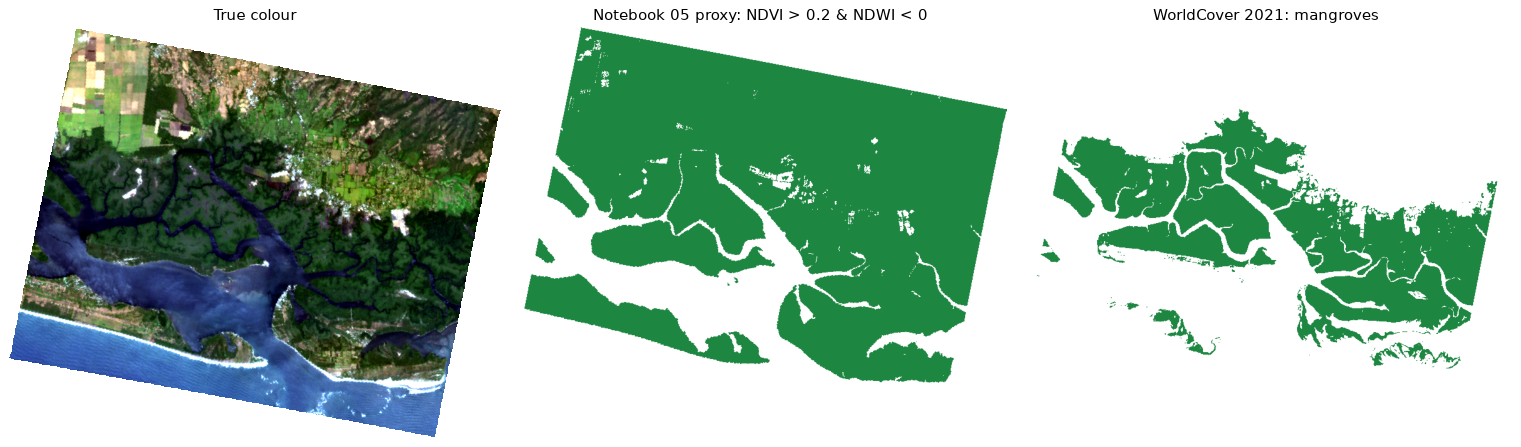

In [2]:
import pandas as pd

SCENE_ID = "20250223_165546_32_4001"   # Jiquilisco Bay, Usulután, El Salvador (coastal-water-bodies)
scene = hu.get_scene(SCENE_ID)
print(scene.summary())

valid = scene.valid_mask()
B = {w: scene.read_band(w) for w in (443, 560, 665, 705, 708, 800, 860, 1650, 2200)}
NDVI = hu.nd(B[800], B[665])            # as in notebook 05
NDWI = hu.nd(B[560], B[860])
NDCI = hu.nd(B[708], B[665])
mangrove_proxy = valid & (NDVI > 0.2) & (NDWI < 0)   # the mask behind notebook 05's "Mangrove proxy"
PIXEL_HA = 0.09

wc, purity = hu.load_labels(SCENE_ID)     # ESA WorldCover 2021 on the Tanager grid (95 = mangroves)
wc_mangrove = valid & (wc == 95)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(scene.rgb()); axes[0].set_title("True colour")
axes[1].imshow(np.where(mangrove_proxy, 1, np.nan), cmap="Greens", vmin=0, vmax=1.3); axes[1].set_title("Notebook 05 proxy: NDVI > 0.2 & NDWI < 0")
axes[2].imshow(np.where(wc_mangrove, 1, np.nan), cmap="Greens", vmin=0, vmax=1.3); axes[2].set_title("WorldCover 2021: mangroves")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Exercise 1 — Proxy area vs reference area  ⭐

1. Compute the area (ha) of the notebook 05 mangrove proxy and of the WorldCover mangrove class.
2. Compute the agreement statistics of the proxy against WorldCover: precision (what fraction of the proxy is
   WorldCover mangrove), recall (what fraction of WorldCover mangrove the proxy finds) and IoU
   (intersection over union).
3. What does the proxy actually map?

### Solution

In [3]:
inter = (mangrove_proxy & wc_mangrove).sum()
union = (mangrove_proxy | wc_mangrove).sum()
print(f"proxy area      : {mangrove_proxy.sum() * PIXEL_HA:9,.0f} ha")
print(f"WorldCover area : {wc_mangrove.sum() * PIXEL_HA:9,.0f} ha")
print(f"precision {inter / mangrove_proxy.sum():.2f}   recall {inter / wc_mangrove.sum():.2f}   IoU {inter / union:.2f}")

counts = pd.Series(wc[mangrove_proxy]).map(lambda c: hu.WORLDCOVER_CLASSES.get(int(c), ("unlabelled",))[0]).value_counts()
print("\nWhat the proxy contains (WorldCover classes, ha):")
print((counts * PIXEL_HA).round(0).to_string())

proxy area      :    23,586 ha
WorldCover area :     9,444 ha
precision 0.40   recall 1.00   IoU 0.40

What the proxy contains (WorldCover classes, ha):
Mangroves                   9424.0
Tree cover                  5697.0
Grassland                   4532.0
Cropland                    2730.0
Permanent water              722.0
Herbaceous wetland           298.0
Built-up                     122.0
Bare / sparse vegetation      46.0
Shrubland                     14.0


**Interpretation:** the proxy finds virtually all WorldCover mangroves (recall ≈ 1.0), but it is about 2.5×
too large (precision ≈ 0.4, IoU ≈ 0.4): it is really a **"any vegetation that is not water"** mask. It
includes the tropical forest, grassland and sugar-cane fields inland. For blue-carbon accounting that would more
than double the carbon stock, so the proxy is a useful first look but not a mangrove map.

## Exercise 2 — What makes a mangrove spectrally different?  ⭐⭐

Compare pure WorldCover **mangrove** (95) pixels with pure **tree cover** (10) and **cropland** (40):

1. Plot the mean spectra of the three classes.
2. Plot their first derivative (dR/dλ) between 650 and 800 nm and report the wavelength of the maximum slope
   (the red-edge position) for each class.
3. In which spectral regions are mangroves most different from the other vegetation?

### Solution

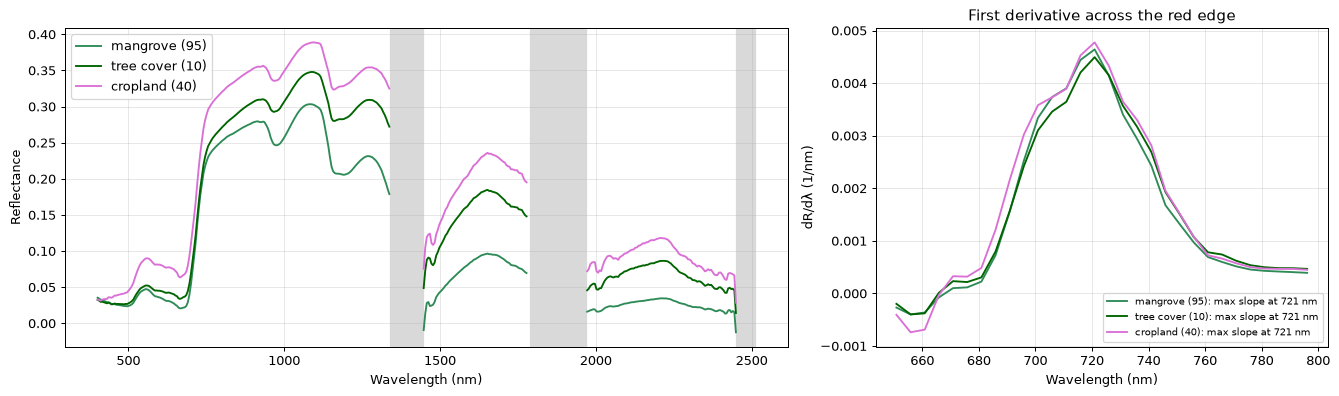

In [4]:
def mean_spectrum(mask, n=500):
    rows, cols = np.nonzero(mask)
    pick = np.random.default_rng(0).choice(len(rows), size=min(n, len(rows)), replace=False)
    rows, cols = rows[pick], cols[pick]
    cube, wl = scene.read_cube((rows.min(), rows.max() + 1, cols.min(), cols.max() + 1))
    return np.nanmean(cube[:, rows - rows.min(), cols - cols.min()], axis=1), wl

classes = {"mangrove (95)": (95, "seagreen"), "tree cover (10)": (10, "darkgreen"), "cropland (40)": (40, "orchid")}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
hu.shade_bad_regions(axes[0])
for name, (code, color) in classes.items():
    spec, wl = mean_spectrum(valid & (wc == code) & (purity == 9) & (NDVI > 0.5))
    hu.plot_spectrum(axes[0], wl, spec, color=color, label=name)
    sel = (wl >= 650) & (wl <= 800)
    d = np.gradient(spec[sel], wl[sel])
    axes[1].plot(wl[sel], d, color=color, label=f"{name}: max slope at {wl[sel][np.argmax(d)]:.0f} nm")
axes[0].set_xlabel("Wavelength (nm)"); axes[0].set_ylabel("Reflectance"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Wavelength (nm)"); axes[1].set_ylabel("dR/dλ (1/nm)"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
axes[1].set_title("First derivative across the red edge")
plt.tight_layout(); plt.show()

**Interpretation**
- **NIR plateau:** mangroves are darker than the inland forest and the crops. Their canopies are dense but
  often have darker, thicker leaves, and a wet, dark substrate (mud, water) shows through the gaps.
- **SWIR** (1500–1800 and 2000–2400 nm): mangroves are clearly the darkest of the three, because of high
  canopy water content and the flooded, dark background. This is the most useful difference, and it is exactly
  the region a broadband NDVI ignores.
- **Red-edge position:** it differs by only a few nanometres between the classes, so it is less useful
  here than the SWIR brightness.

## Exercise 3 — A better mangrove rule, learned from data  ⭐⭐⭐

Train a small, interpretable **decision tree** that separates mangroves from other vegetation, and test it
**on a different part of the scene**:

1. Features per pixel: NDVI, NDWI, NDCI, NDRE (860/705), NDMI (860/1650) and reflectance at 860 and 1650 nm.
2. Training data: pure WorldCover pixels (purity = 9) of classes 95 (mangrove = 1) and 10, 30, 40 (other
   vegetation = 0) in the **western** part of the scene (column < 390). Test data: the same classes in the
   **eastern** part (column ≥ 390).
3. Fit `DecisionTreeClassifier(max_depth=2, class_weight="balanced")`, print the rules and report precision,
   recall and IoU on the test pixels. Compare with the notebook 05 proxy on the same test pixels.
4. Apply the tree to **all** valid pixels of the eastern half. What goes wrong if you don't first restrict it to
   vegetated pixels?

### Solution

In [5]:
from sklearn.tree import DecisionTreeClassifier, export_text

features = {"NDVI": NDVI, "NDWI": NDWI, "NDCI": NDCI, "NDRE": hu.nd(B[860], B[705]),
            "NDMI": hu.nd(B[860], B[1650]), "R860": B[860], "R1650": B[1650]}
X = np.stack(list(features.values()), axis=-1)
finite = np.all(np.isfinite(X), axis=-1)
cols = np.indices(wc.shape)[1]
veg_ref = valid & finite & (purity == 9) & np.isin(wc, [10, 30, 40, 95])
y = wc == 95
train, test = veg_ref & (cols < 390), veg_ref & (cols >= 390)
print(f"training pixels: {train.sum():,} (mangrove share {y[train].mean():.0%}),  test pixels: {test.sum():,}")

clf = DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=0).fit(X[train], y[train])
print(export_text(clf, feature_names=list(features), decimals=3))

def scores(pred, truth):
    tp = (pred & truth).sum()
    return tp / pred.sum(), tp / truth.sum(), tp / (pred | truth).sum()

for name, pred in (("decision tree", clf.predict(X[test]).astype(bool)), ("notebook 05 proxy", mangrove_proxy[test])):
    p, r, iou = scores(pred, y[test])
    print(f"{name:18s} precision {p:.2f}  recall {r:.2f}  IoU {iou:.2f}")

training pixels: 95,893 (mangrove share 48%),  test pixels: 113,906
|--- R1650 <= 0.146
|   |--- R1650 <= 0.136
|   |   |--- class: True
|   |--- R1650 >  0.136
|   |   |--- class: True
|--- R1650 >  0.146
|   |--- R1650 <= 0.158
|   |   |--- class: False
|   |--- R1650 >  0.158
|   |   |--- class: False

decision tree      precision 0.95  recall 0.97  IoU 0.92
notebook 05 proxy  precision 0.46  recall 1.00  IoU 0.46


tree on ALL pixels               precision 0.52  recall 0.96  IoU 0.51  area 9,311 ha
tree inside the vegetation mask  precision 0.87  recall 0.96  IoU 0.83  area 5,607 ha
notebook 05 proxy                precision 0.39  recall 1.00  IoU 0.39  area 12,955 ha


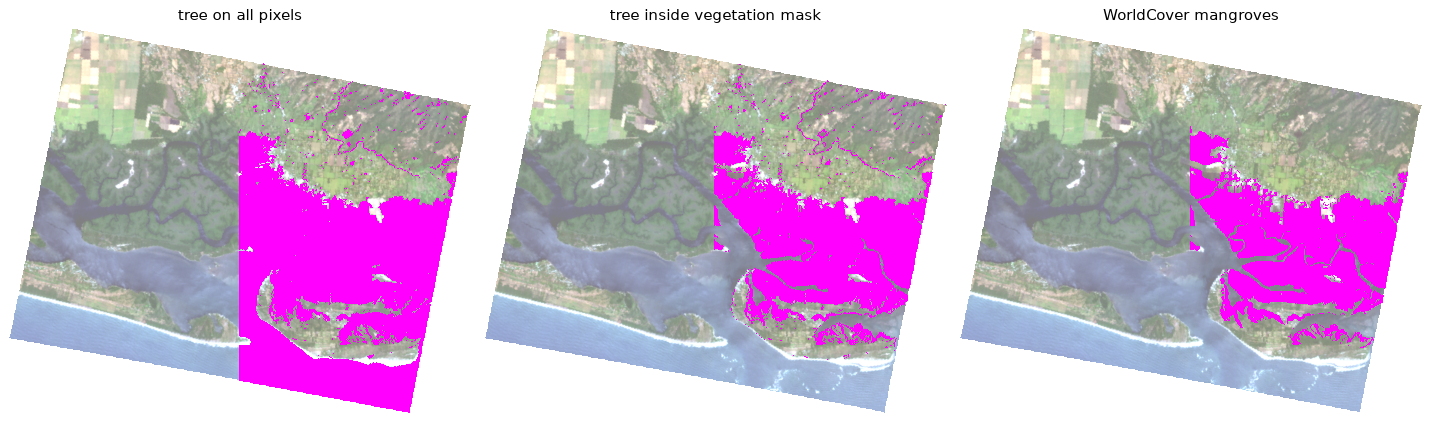

In [6]:
east = valid & finite & (cols >= 390)
tree_all = np.zeros_like(east); tree_all[east] = clf.predict(X[east])
tree_veg = tree_all & mangrove_proxy                 # only where there is vegetation
truth = wc_mangrove & east
for name, pred in (("tree on ALL pixels", tree_all), ("tree inside the vegetation mask", tree_veg),
                   ("notebook 05 proxy", mangrove_proxy & east)):
    p, r, iou = scores(pred & east, truth)
    print(f"{name:32s} precision {p:.2f}  recall {r:.2f}  IoU {iou:.2f}  area {(pred & east).sum() * PIXEL_HA:,.0f} ha")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (title, m) in zip(axes, (("tree on all pixels", tree_all), ("tree inside vegetation mask", tree_veg),
                                  ("WorldCover mangroves", truth))):
    ax.imshow(scene.rgb(), alpha=0.5); ax.imshow(np.where(m & east, 1, np.nan), cmap="spring", interpolation="nearest")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretation**
- With only two levels, the tree reaches a test IoU of about 0.9 on pure pixels, against about 0.45 for the
  proxy. The main split is on **R₁₆₅₀**: mangroves are dark in the SWIR, confirming Exercise 2.
  Because the tree was tested on the *other half* of the scene, this is an honest estimate of how well the
  rule transfers (spatial hold-out).
- Applied to **all** pixels, the tree also flags **water** as mangrove. It has never seen water, and water is
  dark in the SWIR too. A model only knows the classes it was trained on, so either add water (and bare soil)
  to the training data or apply the model inside a mask. Inside the vegetation mask the result is far better
  than the proxy.
- The remaining errors are mostly at forest–mangrove transitions and in mixed pixels, and part of them are
  WorldCover's own errors or changes since 2021.

## Exercise 4 — From hectares to blue carbon — with uncertainty  ⭐⭐

Blue-carbon projects convert **mapped area × carbon density** into a carbon stock. Published
total-ecosystem carbon densities for mangroves (trees + soil down to ~1 m) vary a lot between regions and
studies. For this exercise use a *low* (400), *central* (700) and *high* (1000) value in Mg C per hectare,
as a plausible range (see e.g. Donato et al., 2011; Kauffman et al., 2020 for real regional values).

1. Compute the stock (Mg C and Mt CO₂-equivalent; 1 Mg C = 44/12 Mg CO₂) for three area estimates: the proxy,
   WorldCover, and your decision tree (inside the vegetation mask, whole scene).
2. Which uncertainty is larger here — the choice of map or the choice of carbon density?

### Solution

In [7]:
m = valid & finite
tree_scene = np.zeros(valid.shape, bool); tree_scene[m] = clf.predict(X[m]); tree_scene &= mangrove_proxy
areas = {"notebook 05 proxy": mangrove_proxy.sum() * PIXEL_HA,
         "WorldCover 2021": wc_mangrove.sum() * PIXEL_HA,
         "decision tree": tree_scene.sum() * PIXEL_HA}
densities = {"low 400": 400, "central 700": 700, "high 1000": 1000}   # Mg C / ha (assumed range)

rows = []
for a_name, a in areas.items():
    rows.append([a_name, round(a)] + [round(a * d * 44 / 12 / 1e6, 2) for d in densities.values()])
table = pd.DataFrame(rows, columns=["map", "area (ha)"] + [f"Mt CO₂e ({k})" for k in densities])
table

,map,area (ha),Mt CO₂e (low 400),Mt CO₂e (central 700),Mt CO₂e (high 1000)
0,notebook 05 proxy,23586,34.59,60.54,86.48
1,WorldCover 2021,9444,13.85,24.24,34.63
2,decision tree,10338,15.16,26.54,37.91


**Interpretation:** WorldCover and the decision tree agree to within roughly 10–20% in area, while the proxy is
about 2.5× larger. The density range (400 → 1000 Mg C/ha) changes the result by a factor of 2.5 too. In a
real project **both** matter: the map error can be reduced with better classification and validation, and the
density uncertainty with regional field inventories (soil cores) and species-specific allometry. Report the
stock as a range, never as a single number, and state the map accuracy and the source of the density values.

## Exercise 5 — Reflection — what would it take to trust a mangrove map?  ⭐

In a short markdown cell: WorldCover served as our "truth", but it is itself a model output from 2021 with a
10 m grid. Describe how you would **validate** a Tanager mangrove map for a blue-carbon project. Cover the
reference data source, the sampling design and the reported metrics.

### Solution

**Model answer**
- **Reference data:** interpret very-high-resolution imagery (≤ 3 m, e.g. Planet VHR or drone surveys)
  acquired close in time to the Tanager scene, complemented by field plots (species, canopy height, soil
  cores for carbon). Global Mangrove Watch or WorldCover can serve as a *comparison*, but not as ground truth.
- **Sampling design:** stratified random sampling of *map* classes (mangrove, other vegetation, water, …) with
  enough samples per stratum (e.g. ≥ 50–100), placed independently of the training data and away from the
  training areas (spatial independence).
- **Metrics:** a confusion matrix with user's and producer's accuracy per class, overall accuracy, and the
  **area-adjusted accuracy with 95% confidence intervals** (Olofsson et al., 2014), so that the mangrove *area*
  is reported with an uncertainty that can be propagated into the carbon estimate.
- **Documentation:** image dates, tidal stage (mangrove edges change with the tide), and a map of where the
  model is uncertain.

## Key takeaways

- 'NDVI > 0.2 and not water' maps vegetation, not mangroves — check proxies against a reference.
- Mangroves are darkest in the SWIR; hyperspectral SWIR bands separate them from inland forest.
- Test models on a different area (spatial hold-out) and apply them only where their training classes exist.
- Carbon stocks need both a validated area and regional carbon densities — report a range.

---

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC  
> 📖 Labels: ESA WorldCover 2021 v200 — CC-BY 4.0